## VIX index correlation

In [56]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    roc_auc_score
)

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.request_api_v2 import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension
from Modules.fibonacci_retracement import FibonacciRetracement
from Modules.fibonacci_extension import FibonacciExtension

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = os.getenv("FRED_API_KEY")
# Output directory for storing downloaded data
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
fred_url = "https://api.stlouisfed.org/fred/series/observations"
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()
# Fibonacciエクステンションをプロットするクラスのインスタンスを作成
fibonacci_extension_v2 = FibonacciExtension() 
# Fibonacciリトレースメントを計算するクラスのインスタンスを作成
fibonacci_retracement = FibonacciRetracement()

In [3]:
# Date range for fetching API s
start = '2010-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
frequency = "d"
aggregation_method = "avg"

#### VIX時系列を取得

In [4]:
vix_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^VIX",
    market=None,
)
vix_df.tail()

取得件数: 4435


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
4430,1285477,^VIX,None,2026-10-14,16.870001,17.450001,14.980000,15.170000,0,15.438,...,15.035599,14.868095,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4431,1285478,^VIX,None,2026-10-15,16.459999,18.010000,16.340000,17.549999,0,15.812,...,15.026890,21.407837,False,NaN,NaN,0.0499,NaN,-5.0,NaN,False
4432,1285479,^VIX,None,2026-10-16,19.990000,22.309999,15.720000,16.020000,0,15.948,...,15.026457,27.524972,True,15.948,NaN,NaN,NaN,NaN,NaN,False
4433,1318186,^VIX,None,2026-10-19,18.440001,18.930000,17.389999,18.370001,0,16.544,...,14.980537,34.171433,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4434,1322446,^VIX,None,2026-10-20,17.309999,0.000000,0.000000,0.000000,0,13.422,...,11.981678,25.941262,False,NaN,15.2012,NaN,-0.186283,NaN,NaN,False


In [5]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"VIX_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = vix_df.copy()
df = df.reset_index()
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df.loc['2026-01-01':end]
df.to_csv(output_path)
df.head()

,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,4232,1285279,^VIX,None,14.51,15.42,14.46,14.85,0,14.572,...,14.787274,-54.729787,False,NaN,NaN,NaN,NaN,NaN,NaN,True
2026-01-05,4233,1285280,^VIX,None,14.90,15.27,14.65,15.14,0,14.776,...,14.735110,-55.814053,False,NaN,NaN,-0.92754,NaN,NaN,NaN,False
2026-01-06,4234,1285281,^VIX,None,14.75,15.21,14.63,15.00,0,14.838,...,14.665879,-57.222744,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-07,4235,1285282,^VIX,None,15.38,15.48,14.83,14.95,0,14.942,...,14.623412,-59.442500,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-08,4236,1285283,^VIX,None,15.45,15.85,15.15,15.69,0,15.126,...,14.608978,-60.035858,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### S&P500時系列を取得

In [6]:
sp500_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^GSPC",
    market=None,
)
sp500_df.tail()

取得件数: 4433


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
4428,1273309,^GSPC,None,2026-10-14,7718.939941,7789.149902,7693.310059,7774.180176,5955580000,7789.460059,...,7640.078165,19.200888,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4429,1273322,^GSPC,None,2026-10-15,7744.060059,7754.149902,7669.660156,7687.310059,6055670000,7771.232031,...,7647.640147,12.080594,True,NaN,NaN,NaN,27.378536,NaN,NaN,False
4430,1318182,^GSPC,None,2026-10-16,7659.439941,7756.839844,7631.770020,7745.319824,5482060000,7763.024023,...,7653.598617,9.433962,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4431,1318187,^GSPC,None,2026-10-19,7690.729980,7731.180176,7684.790039,7702.770020,4587260000,7740.970020,...,7660.913979,12.037907,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4432,1322447,^GSPC,None,2026-10-20,7712.569824,7748.419922,7668.029785,7679.009766,5004770000,7717.717969,...,7667.092991,10.475540,False,NaN,7723.472031,NaN,NaN,NaN,NaN,False


#### Nasdaq100時系列を取得

In [7]:
qqq_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^IXIC",
    market=None,
)
qqq_df.tail()

取得件数: 4256


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
4251,1322439,^IXIC,None,2026-10-14,26692.869141,27134.289062,26602.119141,27031.640625,8568280000,27256.235938,...,26401.467814,61.640912,True,NaN,NaN,NaN,245.967145,NaN,NaN,False
4252,1322440,^IXIC,None,2026-10-15,26713.029297,26754.019531,26308.849609,26380.769531,10869960000,27049.183984,...,26437.072969,55.809784,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4253,1322441,^IXIC,None,2026-10-16,26140.029297,26674.660156,26023.099609,26652.980469,9505000000,26911.326172,...,26465.504547,52.565525,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4254,1322442,^IXIC,None,2026-10-19,26430.890625,26613.150391,26344.669922,26395.289062,7537660000,26719.882031,...,26505.571508,51.967899,False,NaN,26916.25625,NaN,NaN,NaN,NaN,False
4255,1322448,^IXIC,None,2026-10-20,26424.820312,26601.710938,26179.730469,26332.919922,7660360000,26558.719922,...,26526.314282,46.008708,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### VIXのフィボナッチリトレースメント実行

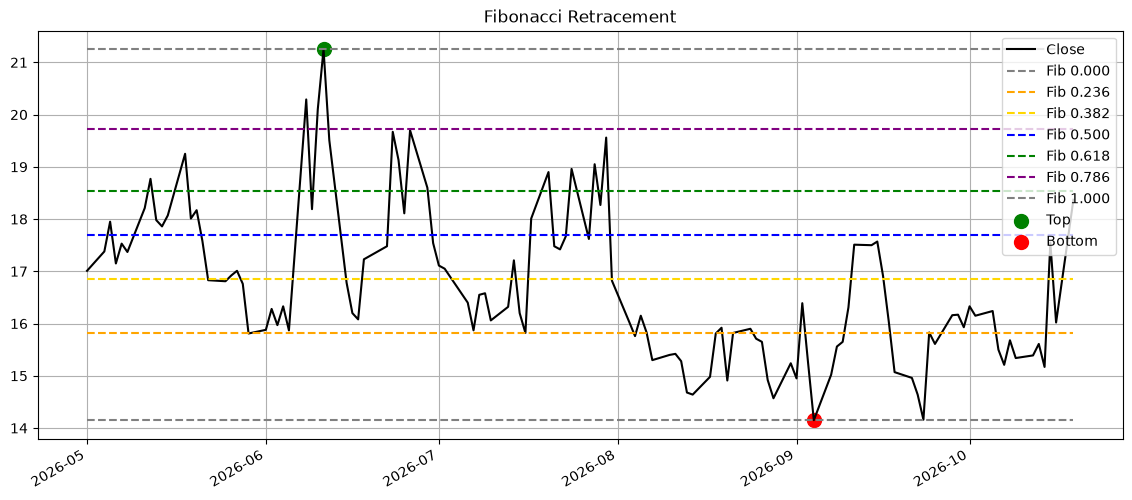

In [8]:
ret = fibonacci_retracement.fibonacci_retracement_technical_chart(df=vix_df)

In [9]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"test_fibonacci_retracement_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 既存の画像ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# 画像ファイルを保存
ret["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")
print("saved:", output_path)

saved: /workspace/data/figures/test_fibonacci_retracement_2026-10-21.png


In [10]:
ret = fibonacci_retracement.fibonacci_retracement_for_timeseries(
    df=vix_df,
    lookback=120,
)
ret

,date,close,fib_trend,fib_top,fib_bottom,fib_retracement_0.000,fib_retracement_0.236,fib_retracement_0.382,fib_retracement_0.500,fib_retracement_0.618,fib_retracement_0.786,fib_retracement_1.000
0,2009-08-27,25.129999,downward,49.680000,23.709999,23.709999,29.838919,33.630540,36.695000,39.759460,44.122420,49.680000
1,2009-08-28,24.440001,downward,45.889999,23.709999,23.709999,28.944479,32.182759,34.799999,37.417239,41.143479,45.889999
2,2009-08-31,24.760000,downward,45.889999,23.709999,23.709999,28.944479,32.182759,34.799999,37.417239,41.143479,45.889999
3,2009-09-01,26.010000,downward,45.889999,23.709999,23.709999,28.944479,32.182759,34.799999,37.417239,41.143479,45.889999
4,2009-09-02,29.139999,downward,45.889999,23.709999,23.709999,28.944479,32.182759,34.799999,37.417239,41.143479,45.889999
...,...,...,...,...,...,...,...,...,...,...,...,...
4310,2026-10-14,15.170000,downward,21.250000,14.150000,14.150000,15.825600,16.862200,17.700000,18.537800,19.730600,21.250000
4311,2026-10-15,17.549999,downward,21.250000,14.150000,14.150000,15.825600,16.862200,17.700000,18.537800,19.730600,21.250000
4312,2026-10-16,16.020000,downward,21.250000,14.150000,14.150000,15.825600,16.862200,17.700000,18.537800,19.730600,21.250000
4313,2026-10-19,18.370001,downward,21.250000,14.150000,14.150000,15.825600,16.862200,17.700000,18.537800,19.730600,21.250000


#### VIXのフィボナッチエクステンション実行

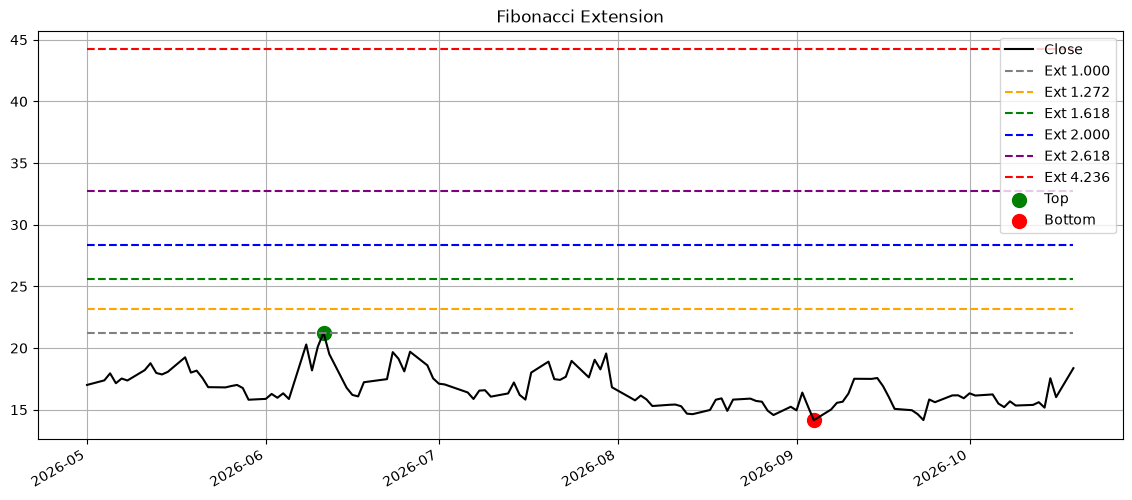

In [11]:
ret = fibonacci_extension_v2.fibonacci_extension_technical_chart(
    df=vix_df,
    lookback=120,
    extension_direction="up"
)

In [12]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"test_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 既存の画像ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# 画像ファイルを保存
ret["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")
print("saved:", output_path)

saved: /workspace/data/figures/test_fibonacci_extension_2026-10-21.png


In [13]:
ret = fibonacci_extension_v2.fibonacci_extension_for_timeseries(
    df=vix_df,
    lookback=120,
    extension_direction="up"
)
ret

,date,close,fib_trend,fib_top,fib_bottom,fib_extension_1.000,fib_extension_1.272,fib_extension_1.618,fib_extension_2.000,fib_extension_2.618,fib_extension_4.236,distance_ext_1272,distance_ext_1618,distance_ext_2000,distance_ext_2618,distance_ext_4236
0,2009-08-27,25.129999,downward,49.680000,23.709999,49.680000,56.743841,65.729461,75.650002,91.699462,133.718924,-31.613841,-40.599462,-50.520002,-66.569463,-108.588925
1,2009-08-28,24.440001,downward,45.889999,23.709999,45.889999,51.922959,59.597240,68.070000,81.777240,117.664480,-27.482959,-35.157239,-43.629999,-57.337239,-93.224480
2,2009-08-31,24.760000,downward,45.889999,23.709999,45.889999,51.922959,59.597240,68.070000,81.777240,117.664480,-27.162959,-34.837239,-43.309999,-57.017240,-92.904480
3,2009-09-01,26.010000,downward,45.889999,23.709999,45.889999,51.922959,59.597240,68.070000,81.777240,117.664480,-25.912959,-33.587239,-42.059999,-55.767240,-91.654480
4,2009-09-02,29.139999,downward,45.889999,23.709999,45.889999,51.922959,59.597240,68.070000,81.777240,117.664480,-22.782960,-30.457240,-38.930000,-52.637240,-88.524481
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4310,2026-10-14,15.170000,downward,21.250000,14.150000,21.250000,23.181200,25.637800,28.350000,32.737801,44.225601,-8.011200,-10.467800,-13.180000,-17.567801,-29.055601
4311,2026-10-15,17.549999,downward,21.250000,14.150000,21.250000,23.181200,25.637800,28.350000,32.737801,44.225601,-5.631201,-8.087801,-10.800001,-15.187801,-26.675602
4312,2026-10-16,16.020000,downward,21.250000,14.150000,21.250000,23.181200,25.637800,28.350000,32.737801,44.225601,-7.161200,-9.617800,-12.330000,-16.717800,-28.205601
4313,2026-10-19,18.370001,downward,21.250000,14.150000,21.250000,23.181200,25.637800,28.350000,32.737801,44.225601,-4.811199,-7.267799,-9.980000,-14.367800,-25.855600


#### 1. フィボナッチ予測値生成

In [14]:
# リトレースメント
retracement_result = (fibonacci_retracement.fibonacci_retracement_for_timeseries(vix_df))
# エクステンション
extension_result = (fibonacci_extension_v2.fibonacci_extension_for_timeseries(vix_df))
# 最新の予測値抽出
fib_ret = retracement_result.copy()
fib_ext = extension_result.copy()
display(fib_ret.tail())
display(fib_ext.tail())

,date,close,fib_trend,fib_top,fib_bottom,fib_retracement_0.000,fib_retracement_0.236,fib_retracement_0.382,fib_retracement_0.500,fib_retracement_0.618,fib_retracement_0.786,fib_retracement_1.000
4310,2026-10-14,15.170000,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4311,2026-10-15,17.549999,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4312,2026-10-16,16.020000,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4313,2026-10-19,18.370001,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4314,2026-10-20,0.000000,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25


,date,close,fib_trend,fib_top,fib_bottom,fib_extension_1.000,fib_extension_1.272,fib_extension_1.618,fib_extension_2.000,fib_extension_2.618,fib_extension_4.236
4310,2026-10-14,15.170000,downward,21.25,14.15,14.15,12.2188,9.762199,7.049999,2.662199,-8.825602
4311,2026-10-15,17.549999,downward,21.25,14.15,14.15,12.2188,9.762199,7.049999,2.662199,-8.825602
4312,2026-10-16,16.020000,downward,21.25,14.15,14.15,12.2188,9.762199,7.049999,2.662199,-8.825602
4313,2026-10-19,18.370001,downward,21.25,14.15,14.15,12.2188,9.762199,7.049999,2.662199,-8.825602
4314,2026-10-20,0.000000,downward,21.25,14.15,14.15,12.2188,9.762199,7.049999,2.662199,-8.825602


#### 2. VIX観測値とFib予測値を統合

In [15]:
research_df = pd.DataFrame()
research_df["date"] = pd.to_datetime(vix_df["date"])
research_df["vix"] = vix_df["close"]
# 実装済クラスの出力列に合わせて修正
research_df["fib_retracement"] = fib_ret["fib_retracement_0.618"]
research_df["fib_extension"] = fib_ext["fib_extension_1.618"]
research_df = research_df.dropna()
display(research_df.tail())

,date,vix,fib_retracement,fib_extension
4310,2026-04-27,19.209999,18.5378,9.762199
4311,2026-04-28,18.299999,18.5378,9.762199
4312,2026-04-29,17.830000,18.5378,9.762199
4313,2026-04-30,18.680000,18.5378,9.762199
4314,2026-05-01,17.010000,18.5378,9.762199


#### 3. EMAによるノイズ除去

In [16]:
# 20日指数移動平均の計算
research_df["vix_ema20"] = (
    research_df["vix"]
    .ewm(span=20)
    .mean()
)
# 20日指数移動平均の計算（フィボナッチリトレースメント）
research_df["fib_ret_ema20"] = (
    research_df["fib_retracement"]
    .ewm(span=20)
    .mean()
)
# 20日指数移動平均の計算（フィボナッチエクステンション）
research_df["fib_ext_ema20"] = (
    research_df["fib_extension"]
    .ewm(span=20)
    .mean()
)


#### 4. Gapの生成

In [17]:
# ギャップの計算（フィボナッチリトレースメントとVIXのEMA20の差）
research_df["gap_ret"] = (
    research_df["fib_ret_ema20"]
    - research_df["vix_ema20"]
)
# ギャップの計算（フィボナッチエクステンションとVIXのEMA20の差）
research_df["gap_ext"] = (
    research_df["fib_ext_ema20"]
    - research_df["vix_ema20"]
)
# ギャップ比率の計算（フィボナッチリトレースメントとVIXのEMA20の差の比率）
research_df["gap_ret_ratio"] = (
    research_df["gap_ret"]
    / research_df["vix_ema20"]
)
# ギャップ比率の計算（フィボナッチエクステンションとVIXのEMA20の差の比率）
research_df["gap_ext_ratio"] = (
    research_df["gap_ext"]
    / research_df["vix_ema20"]
)


#### 5. Rolling Correlation

In [18]:
# 20日および60日移動相関の計算（フィボナッチリトレースメント）
research_df["corr20_ret"] = (
    research_df["vix_ema20"]
    .rolling(20)
    .corr(
        research_df["fib_ret_ema20"]
    )
)
# 20日および60日移動相関の計算（フィボナッチエクステンション）
research_df["corr60_ret"] = (
    research_df["vix_ema20"]
    .rolling(60)
    .corr(
        research_df["fib_ret_ema20"]
    )
)
# 20日および60日移動相関の計算（フィボナッチエクステンション）
research_df["corr20_ext"] = (
    research_df["vix_ema20"]
    .rolling(20)
    .corr(
        research_df["fib_ext_ema20"]
    )
)
# 20日および60日移動相関の計算（フィボナッチエクステンションとVIXのEMA20の相関）
research_df["corr60_ext"] = (
    research_df["vix_ema20"]
    .rolling(60)
    .corr(
        research_df["fib_ext_ema20"]
    )
)

#### 6. 相関変化率生成

In [19]:
# 20日移動相関の傾きの計算（フィボナッチリトレースメント）
research_df["corr20_ret_slope"] = (
    research_df["corr20_ret"]
    .diff()
)

# 20日移動相関の傾きの計算（フィボナッチエクステンション）
research_df["corr20_ext_slope"] = (
    research_df["corr20_ext"]
    .diff()
)

#### 7. 将来VIX上昇率生成

In [20]:
# VIXの将来リターンの計算（5日）
research_df["vix_5d_return"] = (
    research_df["vix"]
    .shift(-5)
    / research_df["vix"]
    - 1
)
# VIXの将来リターンの計算（10日）
research_df["vix_10d_return"] = (
    research_df["vix"]
    .shift(-10)
    / research_df["vix"]
    - 1
)
# VIXの将来リターンの計算（20日）
research_df["vix_20d_return"] = (
    research_df["vix"]
    .shift(-20)
    / research_df["vix"]
    - 1
)

#### 8. 特徴量と将来VIX上昇率の相関

In [21]:
# 相関分析の対象列の設定
target_cols = [
    "vix_5d_return",
    "vix_10d_return",
    "vix_20d_return"
]
# 相関分析の特徴量列の設定
feature_cols = [
    "gap_ret",
    "gap_ext",
    "gap_ret_ratio",
    "gap_ext_ratio",
    "corr20_ret",
    "corr20_ext",
    "corr20_ret_slope",
    "corr20_ext_slope"
]
# 相関分析の結果を格納するDataFrameの初期化
corr_result = pd.DataFrame()
# 各特徴量と各対象列の相関を計算して結果を格納
for feature in feature_cols:
    # 特徴量ごとの相関を計算する行を初期化
    row = {"feature": feature}
    # 各対象列との相関を計算
    for target in target_cols:
        # 対象列ごとの相関を計算
        row[target] = (
            research_df[[feature, target]]
            .corr()
            .iloc[0,1]
        )
    # 計算結果をcorr_resultに追加
    corr_result = pd.concat(
        [
            corr_result,
            pd.DataFrame([row])
        ],
        ignore_index=True
    )
# 相関結果をvix_10d_returnでソート
corr_result = corr_result.sort_values(
    "vix_10d_return",
    ascending=False
)
# 相関結果を表示
display(corr_result)

,feature,vix_5d_return,vix_10d_return,vix_20d_return
0,gap_ret,0.261531,0.350354,0.423816
2,gap_ret_ratio,0.245362,0.333833,0.428419
1,gap_ext,0.087165,0.162090,0.302816
3,gap_ext_ratio,0.080914,0.154757,0.300282
6,corr20_ret_slope,0.044824,0.084205,0.036107
4,corr20_ret,0.042600,0.030803,-0.036469
5,corr20_ext,-0.026422,-0.009309,0.029402
7,corr20_ext_slope,-0.059481,-0.055380,-0.020349


#### 9. 相関符号反転イベント検出

In [22]:
# 相関の符号変化イベントの検出
research_df["corr_sign"] = np.sign(
    research_df["corr20_ext"]
)
# 相関の符号が変化したイベントを検出
research_df["cross_event"] = (
    research_df["corr_sign"]
    !=
    research_df["corr_sign"].shift(1)
)
# 符号変化イベントのみを抽出
cross_df = research_df[
    research_df["cross_event"]
]
# 符号変化イベントの内容を表示
display(
    cross_df[
        [
            "date",
            "vix",
            "corr20_ext",
            "vix_10d_return"
        ]
    ]
)

,date,vix,corr20_ext,vix_10d_return
0,2009-03-09,49.349998,NaN,-0.070111
1,2009-03-10,49.680000,NaN,-0.129630
2,2009-03-11,43.349998,NaN,-0.023068
3,2009-03-12,43.529999,NaN,-0.029405
4,2009-03-13,40.990002,NaN,-0.015370
...,...,...,...,...
4219,2025-12-12,14.990000,-0.264919,-0.020013
4233,2026-01-05,15.140000,0.316501,0.317041
4246,2026-01-23,15.680000,-0.276525,0.354592
4296,2026-04-07,25.090000,0.123377,-0.235552


In [23]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"research_df_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = research_df.copy()
df = df.reset_index()
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df.loc['2026-01-01':end]
df.to_csv(output_path)
df.head()

,index,vix,fib_retracement,fib_extension,vix_ema20,fib_ret_ema20,fib_ext_ema20,gap_ret,gap_ext,gap_ret_ratio,...,corr60_ret,corr20_ext,corr60_ext,corr20_ret_slope,corr20_ext_slope,vix_5d_return,vix_10d_return,vix_20d_return,corr_sign,cross_event
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,4232,14.85,22.654939,47.585058,15.811994,22.276970,47.944190,6.464976,32.132196,0.408865,...,-0.571442,-0.021077,0.299562,-0.060252,0.427683,0.055892,0.039731,0.343434,-1.0,False
2026-01-05,4233,15.14,22.654939,47.585058,15.747995,22.312967,47.909987,6.564972,32.161992,0.416877,...,-0.585301,0.316501,0.214768,-0.045991,0.337578,0.060766,0.317041,0.067371,1.0,True
2026-01-06,4234,15.00,22.654939,47.585058,15.676757,22.345536,47.879041,6.668778,32.202284,0.425393,...,-0.598437,0.522865,0.124578,-0.033455,0.206364,0.024000,0.287333,0.175333,1.0,False
2026-01-07,4235,14.95,22.908319,47.331678,15.607542,22.399134,47.826912,6.791592,32.219369,0.435148,...,-0.609950,0.642184,0.029891,-0.017207,0.119319,0.092308,0.113712,0.286957,1.0,False
2026-01-08,4236,15.69,22.908319,47.331678,15.615395,22.447628,47.779747,6.832233,32.164351,0.437532,...,-0.622320,0.705683,-0.053629,-0.006650,0.063499,0.052900,-0.000637,0.353729,1.0,False


In [24]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"cross_df_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = cross_df.copy()
df = df.reset_index()
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df.loc['2026-01-01':end]
df.to_csv(output_path)
df.head()

,index,vix,fib_retracement,fib_extension,vix_ema20,fib_ret_ema20,fib_ext_ema20,gap_ret,gap_ext,gap_ret_ratio,...,corr60_ret,corr20_ext,corr60_ext,corr20_ret_slope,corr20_ext_slope,vix_5d_return,vix_10d_return,vix_20d_return,corr_sign,cross_event
date,,,,,,,,,,,,,,,,,,,,,
2026-01-05,4233,15.14,22.654939,47.585058,15.747995,22.312967,47.909987,6.564972,32.161992,0.416877,...,-0.585301,0.316501,0.214768,-0.045991,0.337578,0.060766,0.317041,0.067371,1.0,True
2026-01-23,4246,15.68,27.743580,3.876421,16.391589,23.266286,43.290977,6.874697,26.899388,0.419404,...,-0.589134,-0.276525,0.097251,0.372205,-0.514929,0.193877,0.354592,0.306760,-1.0,True
2026-04-07,4296,25.09,18.537800,9.762199,25.760018,23.269466,5.560518,-2.490552,-20.199500,-0.096683,...,0.215089,0.123377,-0.781475,0.034949,0.283391,-0.253487,-0.235552,NaN,1.0,True
2026-04-14,4301,18.73,18.537800,9.762199,23.599500,21.406503,7.214814,-2.192997,-16.384686,-0.092926,...,-0.179247,-0.153861,-0.751520,0.254187,-0.186521,0.024026,-0.022958,NaN,-1.0,True


#### 10. 可視化

saved: /workspace/data/figures/vix_fib_correlation_result_2026-10-21.png


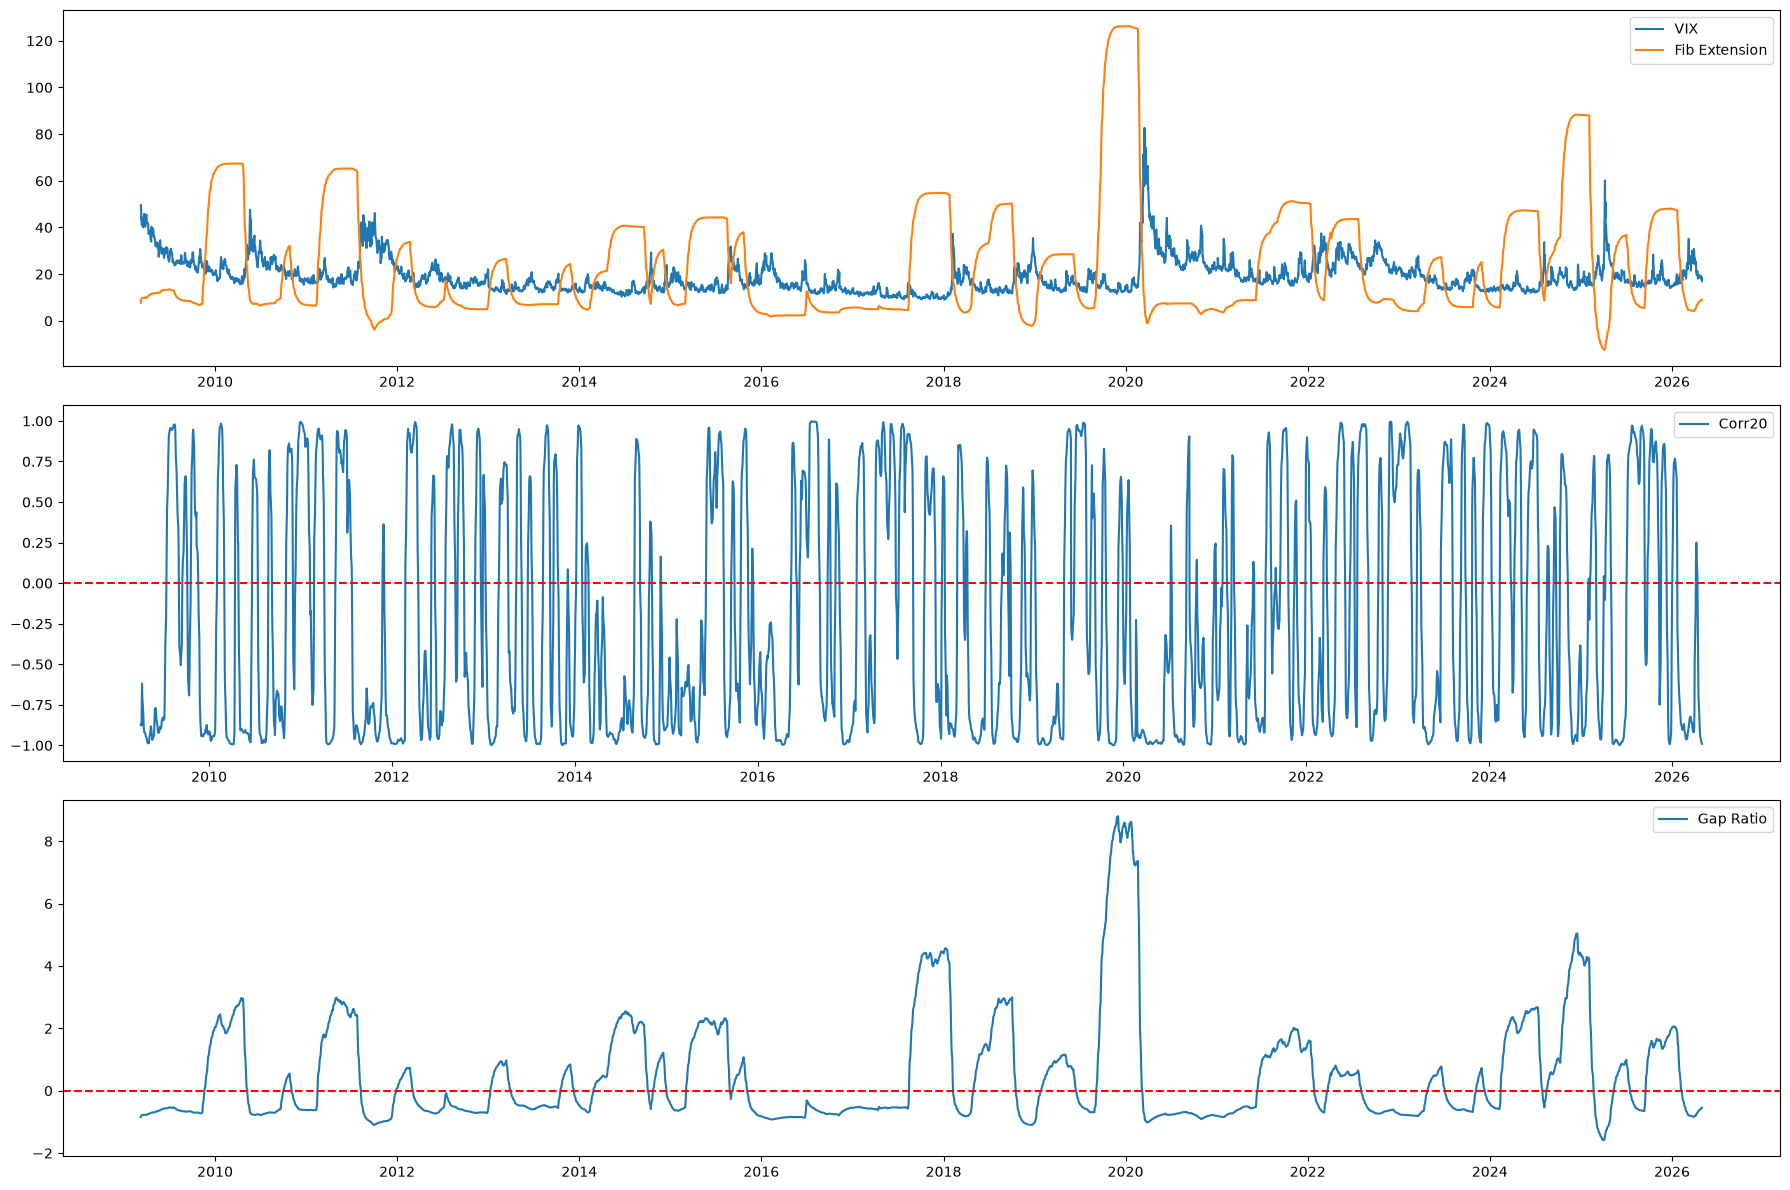

In [25]:

# VIX、Fib Extension、相関、Gap Ratioの時系列プロット
fig, axes = plt.subplots(
    3,
    1,
    figsize=(18, 12)
)
# VIXとFib Extensionのプロット
axes[0].plot(
    research_df["date"],
    research_df["vix"],
    label="VIX"
)
# VIXとFib Extensionのプロットのラベル設定
axes[0].plot(
    research_df["date"],
    research_df["fib_ext_ema20"],
    label="Fib Extension"
)
# VIXとFib Extensionのプロットのラベル設定
axes[0].legend()
# 相関のプロット
axes[1].plot(
    research_df["date"],
    research_df["corr20_ext"],
    label="Corr20"
)
# 相関が0を横切るラインを追加
axes[1].axhline(
    0,
    color="red",
    linestyle="--"
)
# 相関のプロットのラベル設定
axes[1].legend()
# Gap Ratioのプロットのラベル設定
axes[2].plot(
    research_df["date"],
    research_df["gap_ext_ratio"],
    label="Gap Ratio"
)
# Gap Ratioが0を横切るラインを追加
axes[2].axhline(
    0,
    color="red",
    linestyle="--"
)
# Gap Ratioのプロットのラベル設定
axes[2].legend()
# プロットのレイアウト調整と表示
plt.tight_layout()
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"vix_fib_correlation_result_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 既存の画像ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# 画像ファイルを保存
fig.savefig(output_path, dpi=300, bbox_inches="tight")
print("saved:", output_path)
plt.show()

#### 11. Gap Ratioイベント作成
GapRatioが特定閾値を超えた日のみ抽出する

In [26]:
# イベント抽出: Gap Ratioが閾値以上のイベントを抽出
threshold_list = [
    0.5,
    1.0,
    2.0,
    3.0,
    4.0
]
event_dict = {}
# 各閾値に対してイベントを抽出し、辞書に格納
for threshold in threshold_list:
    # 閾値以上のGap Ratioイベントを抽出
    event_df = research_df[
        research_df["gap_ext_ratio"] >= threshold
    ].copy()
    # 日付をインデックスに設定
    event_dict[threshold] = event_df
    print(
        f"GapRatio >= {threshold} : "
        f"{len(event_df)} events"
    )

GapRatio >= 0.5 : 1586 events
GapRatio >= 1.0 : 1199 events
GapRatio >= 2.0 : 737 events
GapRatio >= 3.0 : 265 events
GapRatio >= 4.0 : 232 events


#### 12. イベント発生後のVIX上昇確率

In [27]:
result_rows = []
# 各閾値に対してVIXの上昇確率を計算
for threshold in threshold_list:
    # 閾値に対応するイベントデータを取得
    event_df = event_dict[threshold]
    # 日付をインデックスに設定
    row = {
        "threshold": threshold,
        "count": len(event_df)
    }
    # 各期間に対してVIXの上昇確率を計算
    for period in [5, 10, 20, 40]:
        # 対象の期間を指定
        target = f"vix_{period}d_return"
        # 対象のカラムが存在するか確認
        if target not in event_df.columns:
            continue
        # VIXの上昇確率を計算
        row[f"{period}d_up_prob"] = (
            event_df[target] > 0
        ).mean()
    # 計算結果をリストに追加
    result_rows.append(row)
# 次の閾値の計算に進む
event_probability_df = pd.DataFrame(result_rows)
display(event_probability_df)

,threshold,count,5d_up_prob,10d_up_prob,20d_up_prob
0,0.5,1586,0.489281,0.516393,0.532787
1,1.0,1199,0.510425,0.541284,0.565471
2,2.0,737,0.540027,0.568521,0.625509
3,3.0,265,0.509434,0.494340,0.611321
4,4.0,232,0.530172,0.512931,0.646552


#### 13. イベント発生後の平均VIX上昇率

In [28]:
result_rows = []
# 各閾値に対してVIXの平均リターンを計算
for threshold in threshold_list:
    # 閾値に対応するイベントデータを取得
    event_df = event_dict[threshold]
    # 日付をインデックスに設定
    row = {
        "threshold": threshold,
        "count": len(event_df)
    }
    # 各期間に対してVIXの平均リターンを計算
    for period in [5, 10, 20, 40]:
        # 対象の期間を指定
        target = f"vix_{period}d_return"
        # 対象のカラムが存在するか確認
        if target not in event_df.columns:
            continue
        # VIXの平均リターンを計算
        row[f"{period}d_mean_return"] = (
            event_df[target].mean()
        )
    # 次の期間の計算に進む
    result_rows.append(row)
# 計算結果をデータフレームに変換
event_return_df = pd.DataFrame(result_rows)
display(event_return_df)

,threshold,count,5d_mean_return,10d_mean_return,20d_mean_return
0,0.5,1586,0.028387,0.057347,0.116084
1,1.0,1199,0.033924,0.071943,0.152189
2,2.0,737,0.039522,0.091446,0.225254
3,3.0,265,0.036099,0.105811,0.283561
4,4.0,232,0.038535,0.105523,0.318693


#### 14. ベースラインとの比較

In [29]:
baseline = {}
# 各期間に対して市場平均のVIXリターンを計算
for period in [5, 10, 20]:
    # 対象の期間を指定
    target = f"vix_{period}d_return"
    # 対象のカラムが存在するか確認
    baseline[target] = (
        research_df[target]
        .mean()
    )
# 計算結果をデータフレームに変換
baseline_df = pd.DataFrame(
    baseline,
    index=["MarketAverage"]
)
display(baseline_df)

,vix_5d_return,vix_10d_return,vix_20d_return
MarketAverage,0.010809,0.017684,0.029068


#### 15. 超過リターン分析

In [30]:
excess_rows = []
# 各閾値に対してVIXの超過リターンを計算
for threshold in threshold_list:
    # 閾値に対応するイベントデータを取得
    event_df = event_dict[threshold]
    # 日付をインデックスに設定
    row = {
        "threshold": threshold
    }
    # 各期間に対して超過リターンを計算
    for period in [5, 10, 20]:
        # 対象の期間を指定
        target = f"vix_{period}d_return"
        # 対象のカラムが存在するか確認
        row[f"{period}d_excess"] = (
            event_df[target].mean()
            -
            research_df[target].mean()
        )
    # 次の期間の計算に進む
    excess_rows.append(row)
# 計算結果をデータフレームに変換
excess_df = pd.DataFrame(excess_rows)
display(excess_df)

,threshold,5d_excess,10d_excess,20d_excess
0,0.5,0.017577,0.039663,0.087017
1,1.0,0.023115,0.054259,0.123121
2,2.0,0.028713,0.073762,0.196186
3,3.0,0.025289,0.088127,0.254493
4,4.0,0.027726,0.087839,0.289625


#### 16. GapRatio閾値別イベントスタディ

saved: /workspace/data/figures/16_event_study_by_gapratio_threshold_2026-10-21.png


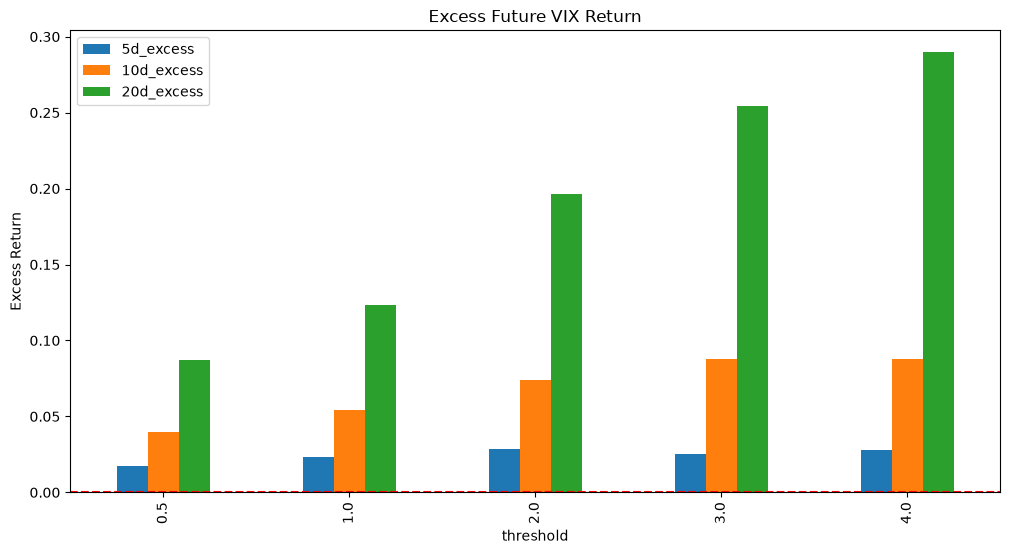

In [31]:

# 閾値をインデックスに設定してプロット用のデータフレームを作成
plot_df = excess_df.set_index(
    "threshold"
)
# プロットを作成
plot_df.plot(
    kind="bar",
    figsize=(12, 6)
)
# 水平線を追加して0を基準にする
plt.axhline(
    0,
    color="red",
    linestyle="--"
)
# タイトルを設定
plt.title(
    "Excess Future VIX Return"
)
# Y軸ラベルを設定
plt.ylabel(
    "Excess Return"
)
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"16_event_study_by_gapratio_threshold_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 既存の画像ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# 画像ファイルを保存
plt.gcf().savefig(output_path, dpi=300, bbox_inches="tight")
print("saved:", output_path)
# 
plt.show()

#### 17. Gap Velocity作成

In [32]:
# ギャップ比率の速度と加速度を計算
research_df["gap_velocity"] = (
    research_df["gap_ext_ratio"]
    .diff()
)
# ギャップ比率の速度の差分を計算
research_df["gap_acceleration"] = (
    research_df["gap_velocity"]
    .diff()
)


#### 18. Gap増加速度イベント

In [33]:
# ギャップ比率の速度が上位5%のイベントを抽出
velocity_threshold = (
    research_df["gap_velocity"]
    .quantile(0.95)
)
# ギャップ比率の速度が上位5%の閾値を計算
velocity_event = research_df[
    research_df["gap_velocity"]
    >= velocity_threshold
]
# ギャップ比率の速度が上位5%のイベントを表示
display(
    velocity_event[
        [
            "date",
            "gap_ext_ratio",
            "gap_velocity",
            "vix_10d_return",
            "vix_20d_return"
        ]
    ]
)

,date,gap_ext_ratio,gap_velocity,vix_10d_return,vix_20d_return
174,2009-11-12,-0.559801,0.139216,0.117621,-0.069010
175,2009-11-13,-0.434587,0.125214,0.028866,-0.109691
176,2009-11-16,-0.318434,0.116153,0.049229,-0.097175
177,2009-11-17,-0.210518,0.107916,-0.040333,-0.084174
178,2009-11-18,-0.109910,0.100608,-0.053691,-0.020582
...,...,...,...,...,...
4162,2025-09-23,0.723035,0.137597,0.029814,0.158385
4163,2025-09-24,0.841533,0.118497,0.036210,0.076645
4164,2025-09-25,0.947831,0.106298,-0.014501,0.109366
4165,2025-09-26,1.038940,0.091109,-0.031379,0.007697


In [34]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"18_gap_increase_rate_event_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = velocity_event.copy()
df = df.reset_index()
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df.to_csv(output_path)
df.head()

,index,vix,fib_retracement,fib_extension,vix_ema20,fib_ret_ema20,fib_ext_ema20,gap_ret,gap_ext,gap_ret_ratio,...,corr60_ext,corr20_ret_slope,corr20_ext_slope,vix_5d_return,vix_10d_return,vix_20d_return,corr_sign,cross_event,gap_velocity,gap_acceleration
date,,,,,,,,,,,,,,,,,,,,,
2009-11-12,174,23.040001,22.198379,43.321617,24.892507,23.820008,10.957658,-1.072499,-13.934849,-0.043085,...,0.535610,0.009190,-0.191470,-0.061198,0.117621,-0.069010,1.0,False,0.139216,0.132582
2009-11-13,175,24.250000,22.198379,43.321617,24.831316,23.665567,14.039939,-1.165749,-10.791376,-0.046947,...,0.345780,0.028054,-0.025710,-0.032990,0.028866,-0.109691,1.0,False,0.125214,-0.014002
2009-11-16,176,23.360001,22.198379,43.321617,24.691190,23.525835,16.828671,-1.165356,-7.862520,-0.047197,...,0.195705,0.049719,-0.027955,-0.059075,0.049229,-0.097175,1.0,False,0.116153,-0.009060
2009-11-17,177,22.809999,22.198379,43.321617,24.512029,23.399410,19.351809,-1.112619,-5.160221,-0.045391,...,0.084836,0.071153,-0.049394,-0.067076,-0.040333,-0.084174,1.0,False,0.107916,-0.008237
2009-11-18,178,22.350000,22.198379,43.321617,24.306122,23.285027,21.634648,-1.021095,-2.671474,-0.042010,...,-0.007469,0.097977,-0.078032,-0.094855,-0.053691,-0.020582,1.0,False,0.100608,-0.007308


#### 19. Fib Extensionリーク検証

##### 目的

Fib Extensionが未来データを参照していないことを確認する。

過去データのみでFib Extensionを再計算し、
現在の実装結果との乖離を確認する。

大きな乖離が発生する場合は
Future Leakageの可能性がある。

In [35]:
# 現在の実装結果
current_fib = research_df["fib_extension"].copy()
# 過去情報のみで再計算
leak_test_result = []
# 過去情報のみでフィボナッチを計算するためのループ
lookback = 120
# 過去情報のみでフィボナッチを計算するためのルックバック期間を設定
for idx in range(len(research_df)):
    # 過去情報のみで計算するため、ルックバック期間に満たない場合はスキップ
    if idx < lookback:
        leak_test_result.append(np.nan)
        continue
    # 過去情報のみで計算するためのデータフレームを作成
    work_df = research_df.iloc[idx - lookback:idx]
    # 過去情報のみでの最高値と最安値を計算
    top = work_df["vix"].max()
    bottom = work_df["vix"].min()
    # 過去情報のみでの差分を計算
    diff = top - bottom
    # フィボナッチの拡張を計算
    fib_extension = top + diff * 0.618
    # 計算結果をリストに追加
    leak_test_result.append(fib_extension)
# 過去情報のみで計算したフィボナッチ拡張をデータフレームに追加
research_df["fib_extension_no_leak"] = leak_test_result
# フィボナッチ拡張の差分を計算
research_df["fib_diff"] = (
    research_df["fib_extension"]
    - research_df["fib_extension_no_leak"]
)
display(
    research_df[
        [
            "date",
            "fib_extension",
            "fib_extension_no_leak",
            "fib_diff"
        ]
    ].tail(30)
)
print(
    "mean abs diff =",
    research_df["fib_diff"].abs().mean()
)


,date,fib_extension,fib_extension_no_leak,fib_diff
4285,2026-03-20,3.866479,48.116538,-44.250059
4286,2026-03-23,3.866479,48.116538,-44.250059
4287,2026-03-24,3.866479,48.116538,-44.250059
4288,2026-03-25,3.866479,48.116538,-44.250059
4289,2026-03-26,3.866479,48.116538,-44.250059
4290,2026-03-27,3.866479,48.116538,-44.250059
4291,2026-03-30,4.645159,48.116538,-43.471379
4292,2026-03-31,6.344659,48.116538,-41.771879
4293,2026-04-01,6.344659,48.116538,-41.771879
4294,2026-04-02,7.389079,48.116538,-40.727459


mean abs diff = 33.930219913711824


#### 20. GapRatio自己相関分析

##### 目的

GapRatioがどの程度連続性を持つかを調査する。

自己相関が高い場合、
イベントスタディにおいて
同一イベントを複数回カウントしている可能性がある。

saved: /workspace/data/figures/20_gap_ratio_autocorrelation_2026-10-22.png


<Figure size 1000x500 with 0 Axes>

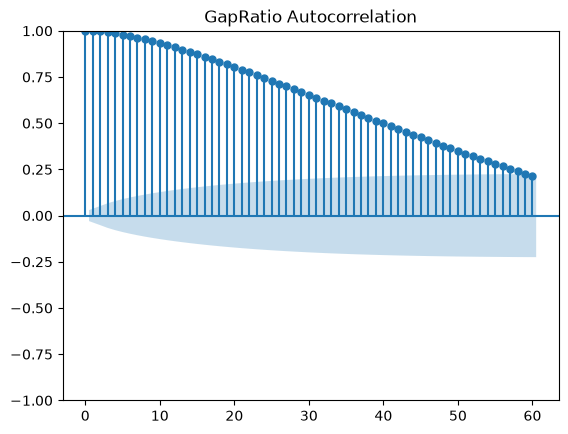

In [ ]:
# ギャップ比率の自己相関をプロット
gap_series = (
    research_df["gap_ext_ratio"]
    .dropna()
)
# ギャップ比率の自己相関を計算してプロットする
plt.figure(figsize=(10, 5))
# 自己相関をプロットする準備
plot_acf(
    gap_series,
    lags=60
)
# 
plt.title(
    "GapRatio Autocorrelation"
)
# 画像保存用のディレクトリとファイルパスを設定
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"20_gap_ratio_autocorrelation_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 既存の画像ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# 画像ファイルを保存
plt.gcf().savefig(output_path, dpi=300, bbox_inches="tight")
print("saved:", output_path)
# プロットを表示
plt.show()

In [38]:
print("Autocorrelation")
# 指定したラグに対するギャップ比率の自己相関を計算して表示
for lag in [1,5,10,20,40]:
    # 現在のラグに対する自己相関を計算
    value = gap_series.autocorr(lag=lag)
    # 計算結果を表示
    print(f"Lag={lag:2d}", round(value, 4))

Autocorrelation
Lag= 1 0.9991
Lag= 5 0.9802
Lag=10 0.934
Lag=20 0.8055
Lag=40 0.5014


#### 21. イベント重複除去

##### 目的

GapRatio閾値イベントが連続発生する場合、
同一ショックを複数回集計してしまう問題を除去する。

イベント検出後、
20営業日のクールダウン期間を設ける。

In [39]:
threshold = 4.0
# Identify independent events based on gap_ext_ratio exceeding the threshold and a cooldown period
event_df = research_df.copy()
# Create a new column "event" to mark rows where the gap_ext_ratio exceeds the threshold
event_df["event"] = (
    event_df["gap_ext_ratio"]
    >= threshold
)
# Set the cooldown period to avoid selecting events that are too close to each other
cooldown = 20
# Select rows that are considered independent events based on the cooldown period
selected_rows = []
# Iterate through the DataFrame to select independent events
last_event_idx = -9999
# 各行を順に確認し、それが独立した事象に該当するかどうかを判定する
for idx in range(len(event_df)):
    # 現在の行が事象に該当するかどうかを確認
    if not event_df.iloc[idx]["event"]:
        continue
    # 前回の事象からクールダウン期間が経過しているか確認
    if idx - last_event_idx < cooldown:
        continue
    # この行は独立した事象として選択される
    selected_rows.append(idx)
    # 更新された行番号を記録して、次の事象の判定に使用
    last_event_idx = idx
# 選択された独立事象に対応する行を抽出する
independent_events = (
    event_df.iloc[selected_rows]
    .copy()
)
# Display the selected independent events with relevant columns
display(
    independent_events[
        [
            "date",
            "gap_ext_ratio",
            "vix_20d_return"
        ]
    ]
)
print(
    "Independent Events =",
    len(independent_events)
)

,date,gap_ext_ratio,vix_20d_return
2157,2017-09-29,4.057541,0.159541
2177,2017-10-27,4.239239,-0.094424
2197,2017-11-27,4.135835,0.011917
2217,2017-12-26,4.458558,0.105986
2237,2018-01-25,4.071174,0.593611
2658,2019-09-27,4.205869,-0.142042
2678,2019-10-25,6.844136,-0.052476
2698,2019-11-22,8.492991,-0.000780
2718,2019-12-23,8.476063,0.035129
2738,2020-01-23,8.598963,0.306938


Independent Events = 14


#### 22. 重複除去後イベントスタディ

##### 目的

独立イベントのみで
20営業日後VIXリターンを再評価する。

In [40]:
# VIXの超過リターンを算出する
for threshold in [0.5, 1, 2, 3, 4]:
    temp = research_df.copy()
    # gap_ext_ratioが閾値を超える行をイベントとしてマークする
    temp["event"] = (
        temp["gap_ext_ratio"]
        >= threshold
    )
    cooldown = 20
    idx_list = []
    last_idx = -9999
    # 各行を順に確認し、それが独立した事象に該当するかどうかを判定する
    for idx in range(len(temp)):
        # 現在の行が事象に該当するかどうかを確認
        if not temp.iloc[idx]["event"]:
            continue
        # 直前の事象からクールダウン期間が経過しているか確認
        if idx - last_idx < cooldown:
            continue
        idx_list.append(idx)
        last_idx = idx
    # サンプルデータフレームを作成
    sample_df = (
        temp.iloc[idx_list]
        .copy()
    )
    # 超過リターンを計算
    excess = (
        sample_df["vix_20d_return"].mean()
        -
        research_df["vix_20d_return"].mean()
    )
    print(
        f"threshold={threshold}",
        f"count={len(sample_df)}",
        f"20d_excess={excess:.4f}"
    )

threshold=0.5 count=90 20d_excess=0.0812
threshold=1 count=68 20d_excess=0.1155
threshold=2 count=45 20d_excess=0.1876
threshold=3 count=15 20d_excess=0.3252
threshold=4 count=14 20d_excess=0.2440


#### 23. Spearman順位相関検定

##### 目的

GapRatioと将来VIX上昇率の
単調関係の有無を検証する。

線形性は仮定しない。

In [42]:
# gap_ext_ratioとvix_20d_returnの間のスピアマン相関を計算する
test_df = research_df[
    [
        "gap_ext_ratio",
        "vix_20d_return"
    ]
].dropna()
# 欠損値を除外したデータフレームを作成
rho, pvalue = spearmanr(
    test_df["gap_ext_ratio"],
    test_df["vix_20d_return"]
)
print(
    "rho    =",
    rho
)
print(
    "pvalue =",
    pvalue
)

rho    = 0.2240202831118767
pvalue = 5.437923204399584e-50


#### 24. Spearman散布図

##### 目的

GapRatioとVIX20日後リターンの関係を
視覚確認する。

saved: /workspace/data/figures/24_gap_ratio_vs_vix_20d_return_2026-10-22.png


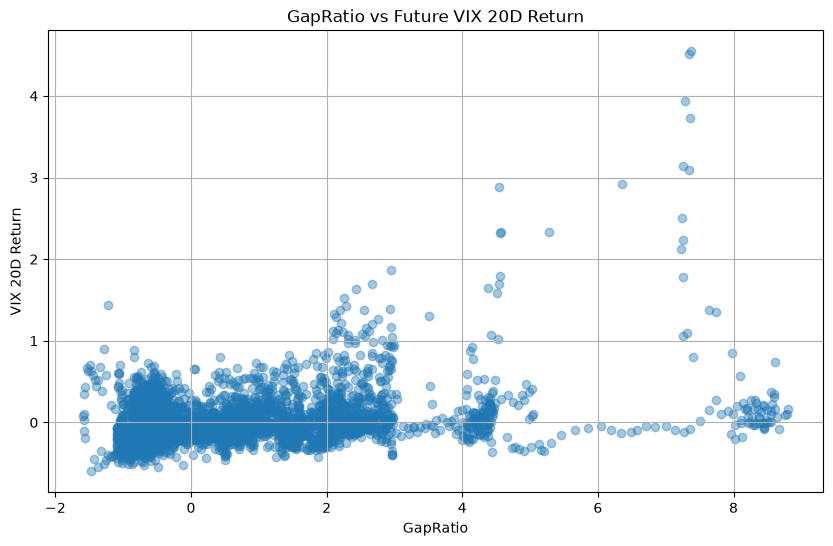

In [43]:
plt.figure(
    figsize=(10, 6)
)
plt.scatter(
    test_df["gap_ext_ratio"],
    test_df["vix_20d_return"],
    alpha=0.4
)
plt.title(
    "GapRatio vs Future VIX 20D Return"
)
plt.xlabel(
    "GapRatio"
)
plt.ylabel(
    "VIX 20D Return"
)
plt.grid()
# 画像保存用のディレクトリとファイルパスを設定
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"24_gap_ratio_vs_vix_20d_return_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 既存の画像ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# 画像ファイルを保存
plt.gcf().savefig(output_path, dpi=300, bbox_inches="tight")
print("saved:", output_path)
plt.show()

#### 25. 重複除去後イベントスタディ(Phase A)

##### 目的

強い自己相関によるイベント重複を除去した後も
GapRatioシグナルが有効であるか検証する。

イベント発生後20営業日は
同一イベントとして扱う。

In [45]:
threshold_list = [0.5, 1.0, 2.0, 3.0, 4.0]
cooldown = 20
result_rows = []
# 各しきい値について順次処理を行い、そのしきい値を超えた事象におけるVIX 20日リターンの超過分を算出する
for threshold in threshold_list:
    last_event_idx = -9999
    selected_idx = []
    # 各事象のインデックスを格納するリストを初期化
    for idx in range(len(research_df)):
        # 現在の事象のギャップ比率を取得
        current_gap = research_df.iloc[idx]["gap_ext_ratio"]
        # ギャップ比率が欠損している場合はスキップ
        if pd.isna(current_gap):
            continue
        # しきい値を下回る場合はスキップ
        if current_gap < threshold:
            continue
        # クールダウン期間内の事象はスキップ
        if idx - last_event_idx < cooldown:
            continue
        # 条件を満たした事象のインデックスを記録
        selected_idx.append(idx)
        last_event_idx = idx
    # 選択された事象のデータフレームを作成
    event_df = research_df.iloc[selected_idx]
    # 選択された事象におけるVIX 20日リターンの平均と全体の平均との差を計算
    excess = (
        event_df["vix_20d_return"].mean()
        -
        research_df["vix_20d_return"].mean()
    )
    result_rows.append({
        "threshold": threshold,
        "count": len(event_df),
        "20d_excess": excess
    })
phase_a_df = pd.DataFrame(result_rows)
display(phase_a_df)


,threshold,count,20d_excess
0,0.5,90,0.081240
1,1.0,68,0.115450
2,2.0,45,0.187591
3,3.0,15,0.325193
4,4.0,14,0.244020


#### 26. VIX急騰確率分析(Phase B)

##### 目的

GapRatio閾値超過時に
将来VIX急騰がどの程度発生するか確認する。

In [46]:
threshold_list = [1, 2, 3, 4]
result_rows = []
# 各しきい値について順次処理を行い、そのしきい値を超えた事象におけるVIX 20日リターンの確率を算出する
for threshold in threshold_list:
    # 現在のしきい値を超えた事象を抽出
    work_df = research_df[
        research_df["gap_ext_ratio"] >= threshold
    ]
    # 現在のしきい値を超えた事象の件数を確認
    result_rows.append({
        "threshold": threshold,
        # 現在のしきい値を超えた事象の件数を記録
        "Prob_VIX_10pct":
        (
            work_df["vix_20d_return"] > 0.10
        ).mean(),
        # 現在のしきい値を超えた事象におけるVIX 20日リターンが10%を超える確率
        "Prob_VIX_20pct":
        (
            work_df["vix_20d_return"] > 0.20
        ).mean(),
        # 現在のしきい値を超えた事象におけるVIX 20日リターンが20%を超える確率
        "Prob_VIX_30pct":
        (
            work_df["vix_20d_return"] > 0.30
        ).mean(),
        # 現在のしきい値を超えた事象におけるVIX 20日リターンが30%を超える確率
        "Count":
        len(work_df)
    })
phase_b_df = pd.DataFrame(result_rows)
display(phase_b_df)

,threshold,Prob_VIX_10pct,Prob_VIX_20pct,Prob_VIX_30pct,Count
0,1,0.407840,0.284404,0.201835,1199
1,2,0.449118,0.322931,0.234735,737
2,3,0.437736,0.294340,0.200000,265
3,4,0.469828,0.314655,0.215517,232


#### 27. VIX急騰確率可視化(Phase B)

saved: /workspace/data/figures/27_Future_VIX_Jump_Probability_2026-10-22.png


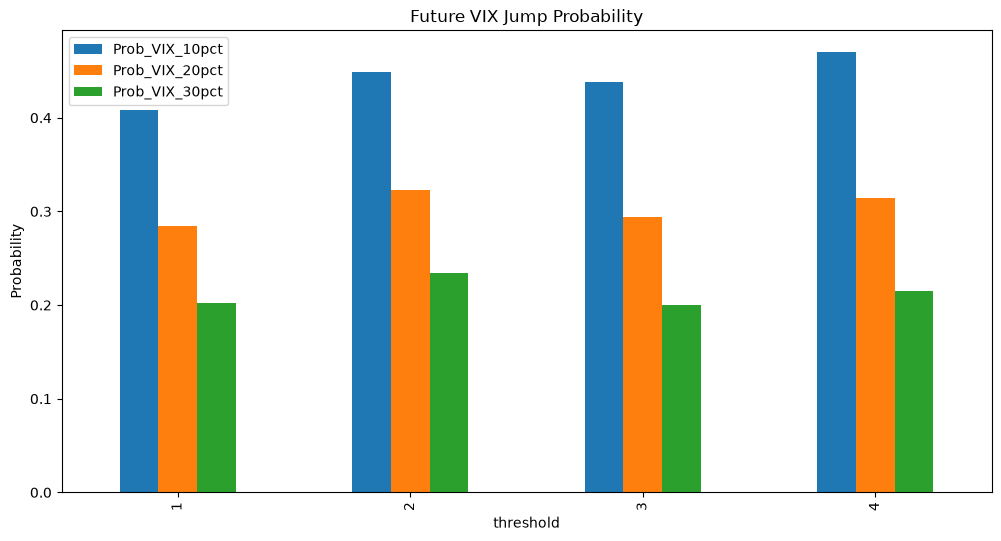

In [47]:
plot_df = phase_b_df.set_index(
    "threshold"
)
plot_df[
    [
        "Prob_VIX_10pct",
        "Prob_VIX_20pct",
        "Prob_VIX_30pct"
    ]
].plot(
    kind="bar",
    figsize=(12,6)
)
plt.title(
    "Future VIX Jump Probability"
)
plt.ylabel(
    "Probability"
)
# 画像保存用のディレクトリとファイルパスを設定
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"27_Future_VIX_Jump_Probability_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 既存の画像ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# 画像ファイルを保存
plt.gcf().savefig(output_path, dpi=300, bbox_inches="tight")
print("saved:", output_path)
plt.show()

#### 28. リード期間探索(Phase C)

##### 目的

GapRatioが最も強く機能する期間を特定する。

In [48]:
periods = [5, 10, 20, 40, 60]
threshold = 4
# しきい値を超えた事象を抽出する
event_df = research_df[
    research_df["gap_ext_ratio"] >= threshold
]
result = []
# 各期間における将来のVIXリターンを計算する
for period in periods:
    # 対象期間のカラム名を作成する
    target_col = f"vix_{period}d_return"
    # 対象期間のカラムが存在しない場合はスキップする
    if target_col not in event_df.columns:
        continue
    # 対象期間の将来リターンを計算して結果に追加する
    result.append({
        "period": period,
        "future_return":
        event_df[target_col].mean()
    })
lead_df = pd.DataFrame(result)
display(lead_df)

,period,future_return
0,5,0.038535
1,10,0.105523
2,20,0.318693


#### 29. リード期間可視化(Phase C)

saved: /workspace/data/figures/29_Lead_Time_Sensitivity_2026-10-22.png


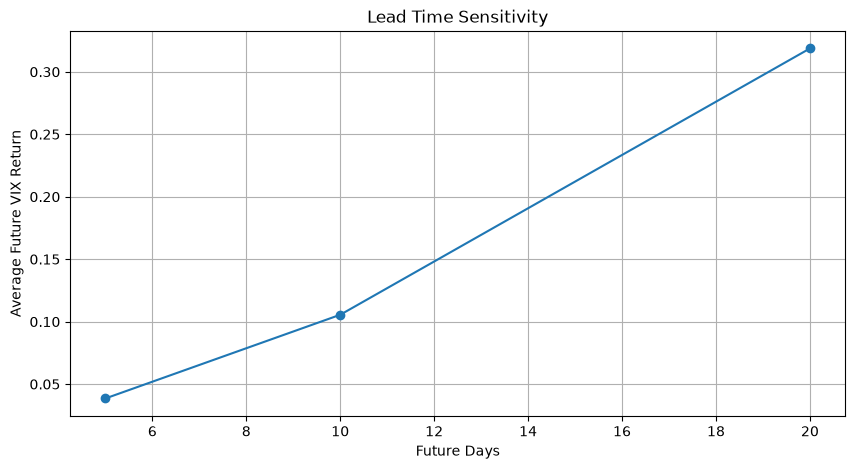

In [49]:
plt.figure(figsize=(10,5))
plt.plot(
    lead_df["period"],
    lead_df["future_return"],
    marker="o"
)
plt.title(
    "Lead Time Sensitivity"
)
plt.xlabel(
    "Future Days"
)
plt.ylabel(
    "Average Future VIX Return"
)
plt.grid()
# 画像保存用のディレクトリとファイルパスを設定
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"29_Lead_Time_Sensitivity_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 既存の画像ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# 画像ファイルを保存
plt.gcf().savefig(output_path, dpi=300, bbox_inches="tight")
print("saved:", output_path)
plt.show()


#### 30. 将来ドローダウン作成(Phase D)

##### 目的

GapRatioが将来の株価下落と関係するか検証する。

In [51]:
forward_window = 20
# 将来の一定期間における最小終値とドローダウンを計算する
sp500_df["future_min_close"] = (
    sp500_df["close"]
    .rolling(forward_window)
    .min()
    .shift(-forward_window)
)
# 将来の一定期間におけるドローダウンを計算する
sp500_df["future_drawdown"] = (
    sp500_df["future_min_close"]
    - sp500_df["close"]
) / sp500_df["close"]

#### 31. GapRatioとSPYドローダウンの結合(Phase D)

In [52]:
# S&P 500の将来のドローダウン情報を抽出する
spy_work = sp500_df[["date", "future_drawdown"]]
# S&P 500の将来のドローダウン情報を抽出して、研究用データフレームと結合する
phase_d_df = pd.merge(
    research_df,
    spy_work,
    on="date",
    how="inner"
)
display(
    phase_d_df[
        [
            "gap_ext_ratio",
            "future_drawdown"
        ]
    ]
    .tail()
)

,gap_ext_ratio,future_drawdown
4310,-0.581138,-0.002951
4311,-0.571440,-0.000299
4312,-0.561504,0.004226
4313,-0.554087,0.009304
4314,-0.543653,-0.000851


#### 32. ドローダウン発生率(Phase D)

In [53]:
threshold_list = [1,2,3,4]
result = []
# 各閾値に対して将来のドローダウンの統計を計算する
for threshold in threshold_list:
    # 閾値以上のギャップ拡張比率を持つデータを抽出する
    work_df = phase_d_df[
        phase_d_df["gap_ext_ratio"]
        >= threshold
    ]
    # 閾値以上のデータが存在しない場合はスキップする
    result.append({
        "threshold": threshold,
        # 将来のドローダウンが5%以上の割合を計算する
        "Drawdown_5pct":
        (
            work_df["future_drawdown"]
            <= -0.05
        ).mean(),
        # 将来のドローダウンが10%以上の割合を計算する
        "Drawdown_10pct":
        (
            work_df["future_drawdown"]
            <= -0.10
        ).mean(),
        # 将来のドローダウンが15%以上の割合を計算する
        "Drawdown_15pct":
        (
            work_df["future_drawdown"]
            <= -0.15
        ).mean()
    })
drawdown_df = pd.DataFrame(result)
display(drawdown_df)

,threshold,Drawdown_5pct,Drawdown_10pct,Drawdown_15pct
0,1,0.145955,0.049208,0.019183
1,2,0.164179,0.066486,0.025780
2,3,0.120755,0.067925,0.045283
3,4,0.125000,0.073276,0.047414


#### 33. 暴落フラグ作成(Phase E)

## 目的

20営業日以内に10%以上下落した場合を
Crash=1とする。

In [54]:
# 将来のドローダウンが10%以上のクラッシュフラグを作成する
phase_d_df["crash_flag"] = (
    phase_d_df["future_drawdown"]
    <= -0.10
).astype(int)
# クラッシュフラグを確認する
phase_d_df[
    [
        "future_drawdown",
        "crash_flag"
    ]
].head()

,future_drawdown,crash_flag
0,-0.002174,0
1,0.059342,0
2,0.001807,0
3,0.043113,0
4,0.002540,0


#### 34. 分類データ作成(Phase E)

In [55]:
# クラッシュ予測モデルの特徴量と目的変数を準備する
feature_cols = [
    "gap_ext_ratio",
    "gap_velocity",
    "gap_acceleration"
]
# モデル用のデータフレームを作成する
model_df = phase_d_df[
    feature_cols + ["crash_flag"]
].dropna()
# 特徴量と目的変数を分割する
X = model_df[feature_cols]
# 目的変数を確認する
y = model_df["crash_flag"]

#### 35. ロジスティック回帰 (Phase E)

In [57]:

# データセットを用いてロジスティック回帰モデルを学習・評価する
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    shuffle=False,
    test_size=0.3
)
# モデルの学習
model = LogisticRegression()
# モデルのインスタンス化
model.fit(
    X_train,
    y_train
)
# 予測の実行
pred = model.predict(X_test)
# 予測確率の取得
prob = model.predict_proba(
    X_test
)[:,1]
print(
    classification_report(
        y_test,
        pred
    )
)
print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        prob
    )
)

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1253
           1       0.00      0.00      0.00        41

    accuracy                           0.97      1294
   macro avg       0.48      0.50      0.49      1294
weighted avg       0.94      0.97      0.95      1294

ROC-AUC: 0.3262219453798688


/workspace/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/workspace/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/workspace/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


#### 36. QQQ将来ドローダウン作成

##### 目的

GapRatio発生時に、
Nasdaq100(QQQ)が将来どの程度下落するかを調査する。

まず将来20営業日以内の最大ドローダウンを算出する。

In [58]:
qqq_work = qqq_df.copy()
# QQQの将来の20日間ドローダウンを算出する
forward_window = 20
# 将来の20日間の最小株価を計算する
future_min = (
    qqq_work["close"]
    .rolling(forward_window)
    .min()
    .shift(-forward_window)
)
# 将来の20日間のドローダウンを計算する
qqq_work["future_drawdown_20d"] = (
    future_min
    - qqq_work["close"]
) / qqq_work["close"]
display(
    qqq_work[
        [
            "date",
            "close",
            "future_drawdown_20d"
        ]
    ]
    .tail()
)

,date,close,future_drawdown_20d
4251,2026-10-14,27031.640625,NaN
4252,2026-10-15,26380.769531,NaN
4253,2026-10-16,26652.980469,NaN
4254,2026-10-19,26395.289062,NaN
4255,2026-10-20,26332.919922,NaN


#### 37. SP500将来ドローダウン作成

##### 目的

S&P500についても
将来20営業日以内の最大ドローダウンを計算する。

In [59]:
# S&P500の将来の20日間ドローダウンを算出する
sp500_work = sp500_df.copy()
# 将来の20日間の最小株価を計算するためのウィンドウを設定する
forward_window = 20
# 将来の最小株価を計算する
future_min = (
    sp500_work["close"]
    .rolling(forward_window)
    .min()
    .shift(-forward_window)
)
# 将来の20日間のドローダウンを計算する
sp500_work["future_drawdown_20d"] = (
    future_min
    - sp500_work["close"]
) / sp500_work["close"]
display(
    sp500_work[
        [
            "date",
            "close",
            "future_drawdown_20d"
        ]
    ]
    .tail()
)

,date,close,future_drawdown_20d
4428,2026-10-14,7774.180176,NaN
4429,2026-10-15,7687.310059,NaN
4430,2026-10-16,7745.319824,NaN
4431,2026-10-19,7702.770020,NaN
4432,2026-10-20,7679.009766,NaN


#### 38. GapRatioとQQQを結合

##### 目的

GapRatioとNasdaq100将来下落率を同一データフレームへ統合する。

In [60]:
qqq_merge_df = pd.merge(
    research_df,
    qqq_work[
        [
            "date",
            "future_drawdown_20d"
        ]
    ],
    on="date",
    how="inner"
)
# QQQの将来の20日間ドローダウンと研究用データをマージする
print(len(qqq_merge_df))
display(
    qqq_merge_df[
        [
            "date",
            "gap_ext_ratio",
            "future_drawdown_20d"
        ]
    ]
    .tail()
)

4138


,date,gap_ext_ratio,future_drawdown_20d
4133,2026-04-27,-0.581138,-0.007787
4134,2026-04-28,-0.571440,-0.000124
4135,2026-04-29,-0.561504,0.010298
4136,2026-04-30,-0.554087,0.004741
4137,2026-05-01,-0.543653,0.005380


#### 39. GapRatioとSP500を結合

##### 目的

GapRatioとS&P500将来下落率を統合する。

In [61]:
sp500_merge_df = pd.merge(
    research_df,
    sp500_work[
        [
            "date",
            "future_drawdown_20d"
        ]
    ],
    on="date",
    how="inner"
)
# S&P500の将来の20日間ドローダウンと研究用データをマージする
print(len(sp500_merge_df))
display(
    sp500_merge_df[
        [
            "date",
            "gap_ext_ratio",
            "future_drawdown_20d"
        ]
    ]
    .tail()
)

4315


,date,gap_ext_ratio,future_drawdown_20d
4310,2026-04-27,-0.581138,-0.002951
4311,2026-04-28,-0.571440,-0.000299
4312,2026-04-29,-0.561504,0.004226
4313,2026-04-30,-0.554087,0.009304
4314,2026-05-01,-0.543653,-0.000851


#### 40. GapRatio閾値別QQQドローダウン発生率

##### 目的

GapRatioが大きいときに
QQQの大幅下落が発生しやすいか確認する。

In [62]:
threshold_list = [1, 2, 3, 4]
result_rows = []
# QQQの将来の20日間ドローダウンを閾値ごとに集計する
for threshold in threshold_list:
    # 閾値以上のギャップ拡張比率を持つデータを抽出する
    work_df = qqq_merge_df[
        qqq_merge_df["gap_ext_ratio"]
        >= threshold
    ]
    # 閾値以上のデータが存在しない場合はスキップする
    result_rows.append({
        "threshold": threshold,
        "Count":
        len(work_df),
        # QQQの将来の20日間ドローダウンが5%以上の割合
        "QQQ_DD_5pct":
        (
            work_df["future_drawdown_20d"]
            <= -0.05
        ).mean(),
        # QQQの将来の20日間ドローダウンが10%以上の割合
        "QQQ_DD_10pct":
        (
            work_df["future_drawdown_20d"]
            <= -0.10
        ).mean(),
        # QQQの将来の20日間ドローダウンが15%以上の割合
        "QQQ_DD_15pct":
        (
            work_df["future_drawdown_20d"]
            <= -0.15
        ).mean()
    })
qqq_drawdown_df = pd.DataFrame(result_rows)
display(qqq_drawdown_df)

,threshold,Count,QQQ_DD_5pct,QQQ_DD_10pct,QQQ_DD_15pct
0,1,1199,0.224354,0.080901,0.026689
1,2,737,0.229308,0.086839,0.033921
2,3,265,0.162264,0.071698,0.049057
3,4,232,0.163793,0.077586,0.051724


#### 41. GapRatio閾値別SP500ドローダウン発生率

##### 目的

GapRatio発生時に
S&P500の大幅下落が増加するか確認する。

In [63]:
result_rows = []
# S&P500の将来の20日間ドローダウンを閾値ごとに集計する
for threshold in threshold_list:
    # 閾値以上のギャップ拡張比率を持つデータを抽出する
    work_df = sp500_merge_df[
        sp500_merge_df["gap_ext_ratio"]
        >= threshold
    ]
    # 閾値以上のデータが存在しない場合はスキップする
    result_rows.append({
        "threshold": threshold,
        "Count":
        len(work_df),
        # S&P500の将来の20日間ドローダウンが5%以上の割合
        "SP500_DD_5pct":
        (
            work_df["future_drawdown_20d"]
            <= -0.05
        ).mean(),
        # S&P500の将来の20日間ドローダウンが10%以上の割合
        "SP500_DD_10pct":
        (
            work_df["future_drawdown_20d"]
            <= -0.10
        ).mean(),
        # S&P500の将来の20日間ドローダウンが15%以上の割合
        "SP500_DD_15pct":
        (
            work_df["future_drawdown_20d"]
            <= -0.15
        ).mean()
    })
sp500_drawdown_df = pd.DataFrame(result_rows)
display(sp500_drawdown_df)


,threshold,Count,SP500_DD_5pct,SP500_DD_10pct,SP500_DD_15pct
0,1,1199,0.145955,0.049208,0.019183
1,2,737,0.164179,0.066486,0.025780
2,3,265,0.120755,0.067925,0.045283
3,4,232,0.125000,0.073276,0.047414


#### 42. QQQドローダウン確率可視化

saved: /workspace/data/figures/42__QQQ_Future_Drawdown_Probability_2026-10-22.png


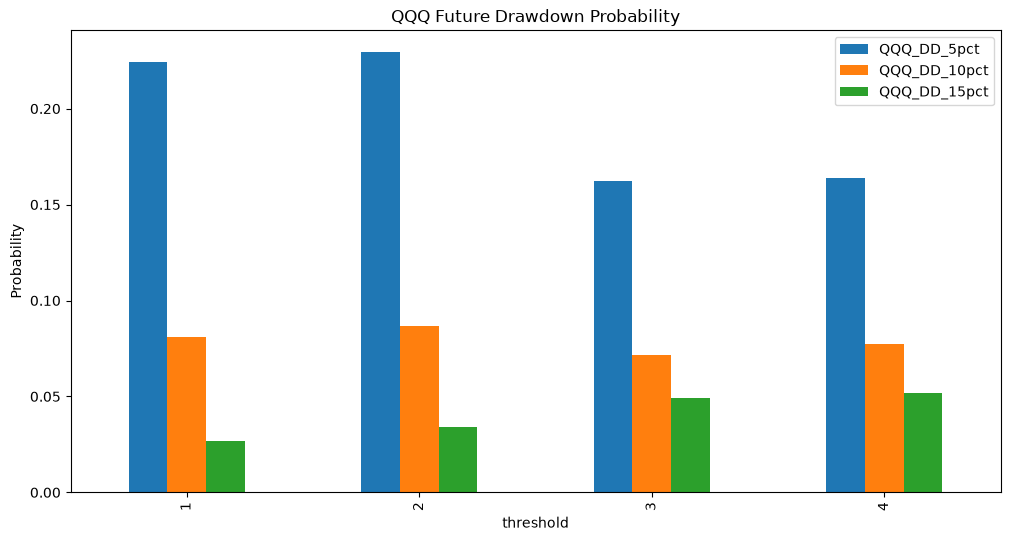

In [64]:
plot_df = qqq_drawdown_df.set_index(
    "threshold"
)
plot_df[
    [
        "QQQ_DD_5pct",
        "QQQ_DD_10pct",
        "QQQ_DD_15pct"
    ]
].plot(
    kind="bar",
    figsize=(12,6)
)
plt.title(
    "QQQ Future Drawdown Probability"
)
plt.ylabel(
    "Probability"
)
# 画像保存用のディレクトリとファイルパスを設定
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"42__QQQ_Future_Drawdown_Probability_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 既存の画像ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# 画像ファイルを保存
plt.gcf().savefig(output_path, dpi=300, bbox_inches="tight")
print("saved:", output_path)
plt.show()

#### 43. S&P500ドローダウン確率可視化

saved: /workspace/data/figures/43_SP500_Future_Drawdown_Probability_2026-10-22.png


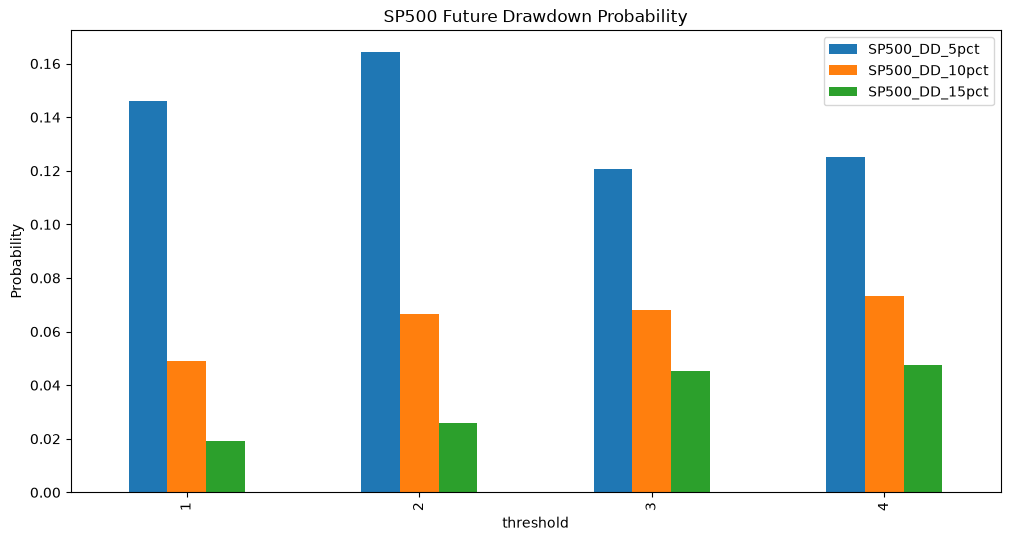

In [65]:
plot_df = sp500_drawdown_df.set_index(
    "threshold"
)
plot_df[
    [
        "SP500_DD_5pct",
        "SP500_DD_10pct",
        "SP500_DD_15pct"
    ]
].plot(
    kind="bar",
    figsize=(12,6)
)
plt.title(
    "SP500 Future Drawdown Probability"
)
plt.ylabel(
    "Probability"
)
# 画像保存用のディレクトリとファイルパスを設定
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"43_SP500_Future_Drawdown_Probability_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 既存の画像ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# 画像ファイルを保存
plt.gcf().savefig(output_path, dpi=300, bbox_inches="tight")
print("saved:", output_path)
plt.show()

#### 44. QQQ将来ドローダウン散布図

##### 目的

GapRatioとQQQ下落率との関係を視覚的に確認する。

saved: /workspace/data/figures/44_GapRatio_vs_Future_QQQ_Drawdown_2026-10-22.png


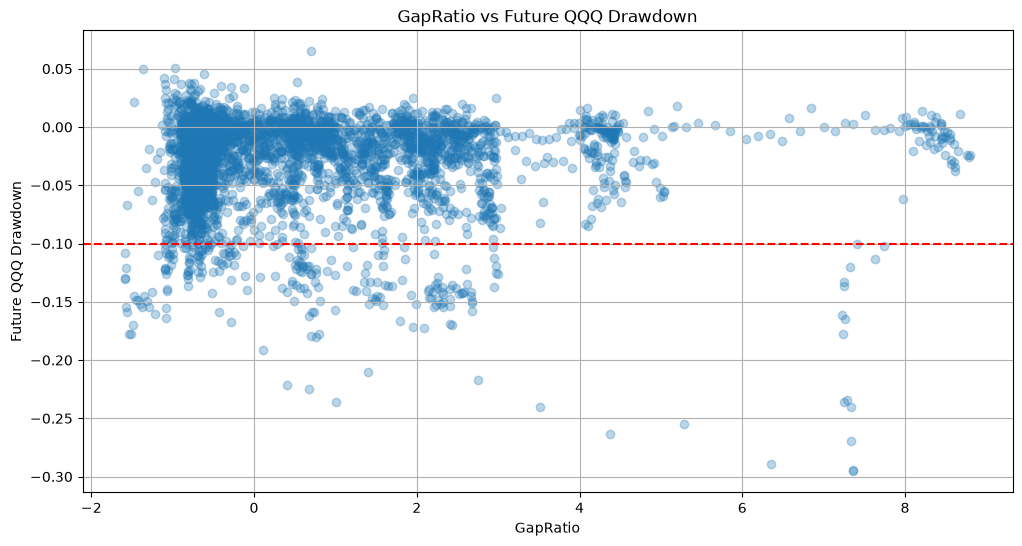

In [66]:
plt.figure(figsize=(12,6))
plt.scatter(
    qqq_merge_df["gap_ext_ratio"],
    qqq_merge_df["future_drawdown_20d"],
    alpha=0.3
)
plt.axhline(
    y=-0.10,
    color="red",
    linestyle="--"
)
plt.xlabel("GapRatio")
plt.ylabel("Future QQQ Drawdown")
plt.title("GapRatio vs Future QQQ Drawdown")
plt.grid()
# 画像保存用のディレクトリとファイルパスを設定
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"44_GapRatio_vs_Future_QQQ_Drawdown_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 既存の画像ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# 画像ファイルを保存
plt.gcf().savefig(output_path, dpi=300, bbox_inches="tight")
print("saved:", output_path)
plt.show()

#### Research Summary

##### Objective

本Notebookの目的は、VIX指数から導出した Fibonacci Extension と VIX の乖離(GapRatio)が、

- 将来のVIX上昇を先行的に検知できるか
- Nasdaq100(QQQ)およびS&P500の大幅下落を検知できるか

を検証することであった。

---

##### Implemented Features

以下の特徴量を作成した。

- Fibonacci Retracement
- Fibonacci Extension
- GapRatio
- GapVelocity
- GapAcceleration

GapRatioは以下の考え方で定義した。

##### VIX Prediction Research
###### Event Study

GapRatioの閾値を変更し、
```
GapRatio > 0.5
GapRatio > 1
GapRatio > 2
GapRatio > 3
GapRatio > 4
```
についてイベントスタディを実施した。

結果として、
```
Threshold ↑
↓
20日後VIX平均上昇率 ↑
```
という関係が確認された。

##### Lead Time Analysis

リード期間を
```
5d
10d
20d
```
で比較した結果、
```
5d  < 10d < 20d
```
となった。

GapRatioは短期シグナルではなく、

約2〜4週間先の市場ストレス増加を示唆する可能性がある。

##### VIX Jump Probability

GapRatio発生時の
```
VIX +10%
VIX +20%
VIX +30%
```
の発生確率を検証した。

結果として、

GapRatioが高い状態では将来VIX急騰確率が上昇する傾向が確認された。

##### Validation
###### Leakage Review

Fib Extensionが未来情報を参照していないことを確認した。

Future Leakageを示す明確な証拠は発見されなかった。

###### Autocorrelation Analysis

GapRatioは非常に強い自己相関を持つことを確認した。

これはGapRatioが市場の状態量(State Variable)として振る舞っていることを示唆する。

一方でイベントスタディでは同一危機イベントを複数回カウントする可能性があるため注意が必要である。

##### QQQ / SP500 Drawdown Research

将来20営業日以内の最大ドローダウンを目的変数として検証した。

###### QQQ

結果は以下の通り。
```
GapRatio ↑
↓
QQQ下落確率 ↑
```

という明確な関係は確認できなかった。

特に
```
QQQ 10% Drawdown Probability
```
は閾値上昇に対してほぼ横ばいであった。

##### SP500

QQQよりは若干の改善が見られたが、

GapRatio単独で強い予測力を持つとは言い難い結果となった。

##### Classification Approach

GapRatio、 GapVelocity、 GapAcceleration

を特徴量としたロジスティック回帰を実施した。

結果
```
ROC-AUC ≈ 0.33
```

##### Conclusions

本研究から得られた結論は以下の通り。

###### Confirmed
- GapRatioは将来のVIX上昇と一定の関係を持つ
- GapRatioは市場ストレスを表す状態量として機能している可能性が高い
- GapRatioのリード期間は短期ではなく20営業日前後である
- GapRatio単独でも将来VIX上昇の警戒指標として利用できる可能性がある
###### Not Confirmed
- GapRatio単独によるNasdaq100暴落予測
- GapRatio単独によるS&P500調整予測
- GapRatio単独による暴落分類モデル構築

##### Final Assessment
GapRatioは`Crash Predictor`ではなく、`Market Stress Indicator`として解釈する方が適切である。

本Notebookの成果は、GapRatioを`L1 Market Regime Detection`の構成要素として利用できる可能性を示したことである。













